# Business-Case Grouped Activity Recognition

This notebook reframes the completed 18-class activity-recognition pipeline as a
three-class business problem:

- `physical_activity`
- `food_or_drink`
- `other_daily_activity`

The intended application is a wearable wellness assistant. Five-second window
predictions provide evidence toward activity monitoring or a possible intake
event; they are not themselves confirmed real-world events.

## 1. Experiment contract and development data

**Question:** Can the established paired-watch representation distinguish the
three business groups across unseen subjects, and is it better to train directly
on the grouped target or aggregate probabilities from the original 18-class
task?

The controlled comparison will use:

1. the frozen 18-class histogram-gradient-boosting configuration, with its class
   probabilities summed into the three business groups;
2. the same configuration trained directly on the three grouped labels.

Both approaches will use the same 25,585 development examples, 222 engineered
features, and five fixed subject-wise folds.

The primary selection metric is mean fold macro-F1. If the two approaches are
within 0.01 macro-F1, mean fold `food_or_drink` precision will be the
business-oriented tie-breaker. If both measures are practically tied, the
direct three-class model will be preferred for simplicity.

The original test set will not be loaded or used in this notebook.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd


CURRENT_DIR = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        candidate
        for candidate in [
            CURRENT_DIR,
            *CURRENT_DIR.parents,
        ]
        if (
            candidate
            / "modeling"
            / "artifacts"
            / "engineered_222_meta.json"
        ).exists()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the activity_project root."
    )

FEATURE_PATH = (
    PROJECT_ROOT
    / "modeling"
    / "artifacts"
    / "engineered_222_train.parquet"
)

FEATURE_META_PATH = (
    PROJECT_ROOT
    / "modeling"
    / "artifacts"
    / "engineered_222_meta.json"
)

TRAIN_METADATA_PATH = (
    PROJECT_ROOT
    / "modified"
    / "watch_pair_20hz"
    / "train_metadata.parquet"
)

DEVELOPMENT_FOLDS_PATH = (
    PROJECT_ROOT
    / "baseline"
    / "artifacts"
    / "development_folds.json"
)

FINAL_MODEL_SPEC_PATH = (
    PROJECT_ROOT
    / "modeling"
    / "artifacts"
    / "final_model_spec.json"
)

BUSINESS_LABELS = [
    "physical_activity",
    "food_or_drink",
    "other_daily_activity",
]

BUSINESS_GROUP_BY_ACTIVITY = {
    "A": "physical_activity",
    "B": "physical_activity",
    "C": "physical_activity",
    "M": "physical_activity",
    "O": "physical_activity",
    "P": "physical_activity",

    "H": "food_or_drink",
    "I": "food_or_drink",
    "J": "food_or_drink",
    "K": "food_or_drink",
    "L": "food_or_drink",

    "D": "other_daily_activity",
    "E": "other_daily_activity",
    "F": "other_daily_activity",
    "G": "other_daily_activity",
    "Q": "other_daily_activity",
    "R": "other_daily_activity",
    "S": "other_daily_activity",
}

print(f"Project root: {PROJECT_ROOT}")

Project root: /Users/yairlutaty/dev/yair.lutaty/projects/activity_project


In [2]:
feature_meta = json.loads(
    FEATURE_META_PATH.read_text(
        encoding="utf-8"
    )
)

development_folds = json.loads(
    DEVELOPMENT_FOLDS_PATH.read_text(
        encoding="utf-8"
    )
)

final_model_spec = json.loads(
    FINAL_MODEL_SPEC_PATH.read_text(
        encoding="utf-8"
    )
)

feature_table = pd.read_parquet(
    FEATURE_PATH
)

train_metadata = pd.read_parquet(
    TRAIN_METADATA_PATH
)

feature_names = feature_meta[
    "feature_names"
]

assert feature_table.columns.tolist() == [
    "array_index",
    *feature_names,
]

assert np.array_equal(
    feature_table["array_index"].to_numpy(),
    train_metadata["array_index"].to_numpy(),
)

X = feature_table[
    feature_names
].to_numpy()

y_activity = (
    train_metadata["activity_code"]
    .astype(str)
    .to_numpy()
)

y_business = (
    pd.Series(y_activity)
    .map(BUSINESS_GROUP_BY_ACTIVITY)
    .to_numpy()
)

fold_assignments = (
    train_metadata["fold"]
    .astype(int)
    .to_numpy()
)

subject_ids = (
    train_metadata["user_id"]
    .astype(int)
    .to_numpy()
)

expected_fold_by_subject = {
    int(subject_id): int(fold)
    for fold, subjects in (
        development_folds[
            "validation_subject_ids_by_fold"
        ].items()
    )
    for subject_id in subjects
}

observed_fold_by_subject = {
    int(row.user_id): int(row.fold)
    for row in (
        train_metadata[
            ["user_id", "fold"]
        ]
        .drop_duplicates()
        .itertuples(index=False)
    )
}

assert X.shape == (25_585, 222)
assert np.isfinite(X).all()
assert set(y_activity) == set(
    BUSINESS_GROUP_BY_ACTIVITY
)
assert not pd.isna(y_business).any()
assert observed_fold_by_subject == (
    expected_fold_by_subject
)

business_coverage = (
    pd.DataFrame({
        "business_label": y_business,
        "user_id": subject_ids,
    })
    .groupby(
        "business_label",
        observed=True,
    )
    .agg(
        examples=("business_label", "size"),
        subjects=("user_id", "nunique"),
    )
    .reindex(BUSINESS_LABELS)
    .reset_index()
)

business_coverage["share"] = (
    business_coverage["examples"]
    / len(y_business)
)

print(f"Examples: {len(y_business):,}")
print(f"Features: {X.shape[1]}")
print(f"Subjects: {np.unique(subject_ids).size}")
print(f"Original activities: {np.unique(y_activity).size}")
print(f"Business groups: {np.unique(y_business).size}")
print(
    "Folds:",
    sorted(np.unique(fold_assignments)),
)
print(
    "Feature rows, metadata, labels, and fixed "
    "subject folds are aligned."
)

business_coverage

Examples: 25,585
Features: 222
Subjects: 41
Original activities: 18
Business groups: 3
Folds: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Feature rows, metadata, labels, and fixed subject folds are aligned.


,business_label,examples,subjects,share
0,physical_activity,8470,41,0.331053
1,food_or_drink,7105,41,0.277702
2,other_daily_activity,10010,41,0.391245


### Development-data findings

The grouped target preserves the full established development population:
25,585 paired-watch examples from 41 subjects, represented by 222 deterministic
features.

All 18 original activities map successfully into exactly three business groups,
and every group contains all 41 development subjects. Group support ranges from
27.8% to 39.1%, so no severe class imbalance is present. The initial comparison
will therefore use the frozen model configuration without class weighting.

Macro-F1 remains appropriate as the primary metric because it gives equal
importance to all three business groups, while food-or-drink precision provides
the main business-oriented diagnostic.

In [3]:
from sklearn.ensemble import (
    HistGradientBoostingClassifier,
)
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
)


HGB_PARAMETERS = (
    final_model_spec[
        "estimator"
    ][
        "parameters"
    ]
    .copy()
)

assert (
    final_model_spec[
        "estimator"
    ][
        "class"
    ]
    == (
        "sklearn.ensemble."
        "HistGradientBoostingClassifier"
    )
)

assert HGB_PARAMETERS[
    "class_weight"
] is None

pd.Series(
    HGB_PARAMETERS,
    name="value",
).to_frame()

,value
learning_rate,0.05
max_iter,200
max_leaf_nodes,31
min_samples_leaf,20
l2_regularization,1.0
early_stopping,False
class_weight,None
random_state,42


In [4]:
def group_metric_table(
    y_true,
    y_pred,
):
    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=BUSINESS_LABELS,
            zero_division=0,
        )
    )

    return pd.DataFrame({
        "business_label": BUSINESS_LABELS,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "support": support.astype(int),
    }).set_index(
        "business_label"
    )


def calculate_business_metrics(
    y_true,
    y_pred,
):
    report = group_metric_table(
        y_true,
        y_pred,
    )

    return {
        "accuracy": accuracy_score(
            y_true,
            y_pred,
        ),
        "balanced_accuracy": (
            report["recall"].mean()
        ),
        "macro_f1": (
            report["f1"].mean()
        ),
        "food_precision": report.loc[
            "food_or_drink",
            "precision",
        ],
        "food_recall": report.loc[
            "food_or_drink",
            "recall",
        ],
        "physical_recall": report.loc[
            "physical_activity",
            "recall",
        ],
    }


def fold_metric_table(
    predictions,
):
    rows = []

    for outer_fold, fold_data in (
        predictions.groupby(
            "outer_fold",
            sort=True,
        )
    ):
        rows.append({
            "fold": int(outer_fold),
            **calculate_business_metrics(
                fold_data["y_true"],
                fold_data["y_pred"],
            ),
        })

    return pd.DataFrame(rows)


def summarize_fold_metrics(
    fold_metrics,
):
    metric_columns = [
        column
        for column in fold_metrics.columns
        if column != "fold"
    ]

    return (
        fold_metrics[
            metric_columns
        ]
        .agg(["mean", "std"])
        .T
        .rename_axis("metric")
    )

## 3. Aggregated 18-class probability reference

This reference preserves the original fine-grained learning task. Within each
subject fold, the histogram-gradient-boosting model is trained to predict all 18
activities. Its validation probabilities are then summed according to the
business mapping.

For example, the probability of `food_or_drink` is the sum of the probabilities
assigned to Eating Soup, Eating Chips, Eating Pasta, Drinking from Cup, and
Eating Sandwich.

Aggregating probabilities is preferable to mapping the model's single predicted
activity because evidence distributed across several activities in the same
business group can contribute to the grouped decision.

In [5]:
from time import perf_counter


business_label_array = np.asarray(
    BUSINESS_LABELS
)

aggregated_prediction_parts = []

for outer_fold in sorted(
    np.unique(fold_assignments)
):
    training_mask = (
        fold_assignments
        != outer_fold
    )
    validation_mask = (
        fold_assignments
        == outer_fold
    )

    training_subjects = set(
        subject_ids[training_mask]
    )
    validation_subjects = set(
        subject_ids[validation_mask]
    )

    assert training_subjects.isdisjoint(
        validation_subjects
    )

    model = HistGradientBoostingClassifier(
        **HGB_PARAMETERS
    )

    start_time = perf_counter()

    model.fit(
        X[training_mask],
        y_activity[training_mask],
    )

    fit_seconds = (
        perf_counter()
        - start_time
    )

    activity_probabilities = (
        model.predict_proba(
            X[validation_mask]
        )
    )

    assert set(
        model.classes_
    ) == set(
        BUSINESS_GROUP_BY_ACTIVITY
    )

    business_probabilities = np.zeros(
        (
            validation_mask.sum(),
            len(BUSINESS_LABELS),
        ),
        dtype=float,
    )

    for group_index, business_label in (
        enumerate(BUSINESS_LABELS)
    ):
        activity_indices = [
            class_index
            for class_index, activity_code
            in enumerate(model.classes_)
            if BUSINESS_GROUP_BY_ACTIVITY[
                str(activity_code)
            ] == business_label
        ]

        business_probabilities[
            :,
            group_index,
        ] = activity_probabilities[
            :,
            activity_indices,
        ].sum(axis=1)

    assert np.allclose(
        business_probabilities.sum(axis=1),
        1.0,
    )

    y_pred = business_label_array[
        business_probabilities.argmax(axis=1)
    ]

    fold_metrics = (
        calculate_business_metrics(
            y_business[validation_mask],
            y_pred,
        )
    )

    fold_predictions = pd.DataFrame({
        "array_index": train_metadata.loc[
            validation_mask,
            "array_index",
        ].to_numpy(),
        "user_id": subject_ids[
            validation_mask
        ],
        "outer_fold": int(outer_fold),
        "activity_true": y_activity[
            validation_mask
        ],
        "y_true": y_business[
            validation_mask
        ],
        "y_pred": y_pred,
    })

    for group_index, business_label in (
        enumerate(BUSINESS_LABELS)
    ):
        fold_predictions[
            f"prob_{business_label}"
        ] = business_probabilities[
            :,
            group_index,
        ]

    aggregated_prediction_parts.append(
        fold_predictions
    )

    print(
        f"Fold {outer_fold}: "
        f"macro-F1="
        f"{fold_metrics['macro_f1']:.4f}, "
        f"food precision="
        f"{fold_metrics['food_precision']:.4f}, "
        f"time={fit_seconds:.1f}s"
    )

aggregated_oof_predictions = (
    pd.concat(
        aggregated_prediction_parts,
        ignore_index=True,
    )
    .sort_values("array_index")
    .reset_index(drop=True)
)

assert len(
    aggregated_oof_predictions
) == len(y_business)

assert (
    aggregated_oof_predictions[
        "array_index"
    ].is_unique
)

assert np.array_equal(
    aggregated_oof_predictions[
        "array_index"
    ].to_numpy(),
    train_metadata[
        "array_index"
    ].to_numpy(),
)

assert np.array_equal(
    aggregated_oof_predictions[
        "y_true"
    ].to_numpy(),
    y_business,
)

print(
    "Complete aggregated out-of-fold "
    "predictions:",
    f"{len(aggregated_oof_predictions):,}",
)

Fold 1: macro-F1=0.9442, food precision=0.9336, time=55.0s
Fold 2: macro-F1=0.8951, food precision=0.8567, time=54.4s
Fold 3: macro-F1=0.9353, food precision=0.9021, time=54.1s
Fold 4: macro-F1=0.8953, food precision=0.8478, time=53.1s
Fold 5: macro-F1=0.8916, food precision=0.8636, time=52.8s
Complete aggregated out-of-fold predictions: 25,585


In [6]:
aggregated_fold_metrics = (
    fold_metric_table(
        aggregated_oof_predictions
    )
)

aggregated_summary = (
    summarize_fold_metrics(
        aggregated_fold_metrics
    )
)

aggregated_group_metrics = (
    group_metric_table(
        aggregated_oof_predictions[
            "y_true"
        ],
        aggregated_oof_predictions[
            "y_pred"
        ],
    )
)

display(
    aggregated_fold_metrics.round(4)
)

display(
    aggregated_summary.round(4)
)

display(
    aggregated_group_metrics.round(4)
)

,fold,accuracy,balanced_accuracy,macro_f1,food_precision,food_recall,physical_recall
0,1,0.9457,0.9420,0.9442,0.9336,0.8844,0.9905
1,2,0.8948,0.8945,0.8951,0.8567,0.8718,0.9331
2,3,0.9358,0.9355,0.9353,0.9021,0.9214,0.9568
3,4,0.8956,0.8933,0.8953,0.8478,0.8491,0.9416
4,5,0.8915,0.8880,0.8916,0.8636,0.8321,0.9313


,mean,std
metric,,
accuracy,0.9127,0.0259
balanced_accuracy,0.9107,0.0259
macro_f1,0.9123,0.0253
food_precision,0.8808,0.0361
food_recall,0.8718,0.0343
physical_recall,0.9507,0.0244


,precision,recall,f1,support
business_label,,,,
physical_activity,0.9845,0.9518,0.9679,8470
food_or_drink,0.8819,0.8722,0.8770,7105
other_daily_activity,0.8790,0.9105,0.8945,10010


### Aggregated-reference findings

Aggregating the 18-class probabilities produces strong subject-independent
three-class performance, with mean macro-F1 0.9123 ± 0.0253.

`physical_activity` is the strongest group, with pooled F1 0.9679 and mean fold
recall 0.9507. `food_or_drink` reaches pooled precision 0.8819 and recall 0.8722,
showing a useful balance rather than achieving high precision by predicting very
few food-or-drink windows.

The lower performance of `food_or_drink` and `other_daily_activity` suggests
that their boundary is the main remaining challenge. Fold variation also
indicates that generalization to unseen wearers remains relevant despite the
strong overall result.

## 4. Direct three-class model

The direct model uses the same examples, features, folds, and frozen
histogram-gradient-boosting configuration. The only change is that it learns the
three business labels directly.

Direct training may improve the boundaries that matter to the product because
the model no longer spends capacity distinguishing activities within the same
business group. Conversely, the fine-grained 18-class labels may provide useful
auxiliary structure, so the outcome must be measured rather than assumed.

In [7]:
direct_prediction_parts = []

for outer_fold in sorted(
    np.unique(fold_assignments)
):
    training_mask = (
        fold_assignments
        != outer_fold
    )
    validation_mask = (
        fold_assignments
        == outer_fold
    )

    training_subjects = set(
        subject_ids[training_mask]
    )
    validation_subjects = set(
        subject_ids[validation_mask]
    )

    assert training_subjects.isdisjoint(
        validation_subjects
    )

    model = HistGradientBoostingClassifier(
        **HGB_PARAMETERS
    )

    start_time = perf_counter()

    model.fit(
        X[training_mask],
        y_business[training_mask],
    )

    fit_seconds = (
        perf_counter()
        - start_time
    )

    model_probabilities = (
        model.predict_proba(
            X[validation_mask]
        )
    )

    assert set(
        model.classes_
    ) == set(
        BUSINESS_LABELS
    )

    class_index_by_label = {
        str(label): class_index
        for class_index, label
        in enumerate(model.classes_)
    }

    business_probabilities = (
        model_probabilities[
            :,
            [
                class_index_by_label[label]
                for label in BUSINESS_LABELS
            ],
        ]
    )

    assert np.allclose(
        business_probabilities.sum(axis=1),
        1.0,
    )

    y_pred = business_label_array[
        business_probabilities.argmax(axis=1)
    ]

    fold_metrics = (
        calculate_business_metrics(
            y_business[validation_mask],
            y_pred,
        )
    )

    fold_predictions = pd.DataFrame({
        "array_index": train_metadata.loc[
            validation_mask,
            "array_index",
        ].to_numpy(),
        "user_id": subject_ids[
            validation_mask
        ],
        "outer_fold": int(outer_fold),
        "activity_true": y_activity[
            validation_mask
        ],
        "y_true": y_business[
            validation_mask
        ],
        "y_pred": y_pred,
    })

    for group_index, business_label in (
        enumerate(BUSINESS_LABELS)
    ):
        fold_predictions[
            f"prob_{business_label}"
        ] = business_probabilities[
            :,
            group_index,
        ]

    direct_prediction_parts.append(
        fold_predictions
    )

    print(
        f"Fold {outer_fold}: "
        f"macro-F1="
        f"{fold_metrics['macro_f1']:.4f}, "
        f"food precision="
        f"{fold_metrics['food_precision']:.4f}, "
        f"time={fit_seconds:.1f}s"
    )

direct_oof_predictions = (
    pd.concat(
        direct_prediction_parts,
        ignore_index=True,
    )
    .sort_values("array_index")
    .reset_index(drop=True)
)

assert len(
    direct_oof_predictions
) == len(y_business)

assert (
    direct_oof_predictions[
        "array_index"
    ].is_unique
)

assert np.array_equal(
    direct_oof_predictions[
        "array_index"
    ].to_numpy(),
    train_metadata[
        "array_index"
    ].to_numpy(),
)

assert np.array_equal(
    direct_oof_predictions[
        "y_true"
    ].to_numpy(),
    y_business,
)

print(
    "Complete direct out-of-fold predictions:",
    f"{len(direct_oof_predictions):,}",
)

Fold 1: macro-F1=0.9499, food precision=0.9577, time=9.4s
Fold 2: macro-F1=0.8930, food precision=0.8692, time=10.3s
Fold 3: macro-F1=0.9379, food precision=0.9267, time=9.5s
Fold 4: macro-F1=0.8975, food precision=0.8564, time=9.4s
Fold 5: macro-F1=0.9005, food precision=0.8939, time=9.8s
Complete direct out-of-fold predictions: 25,585


In [8]:
direct_fold_metrics = (
    fold_metric_table(
        direct_oof_predictions
    )
)

direct_summary = (
    summarize_fold_metrics(
        direct_fold_metrics
    )
)

direct_group_metrics = (
    group_metric_table(
        direct_oof_predictions[
            "y_true"
        ],
        direct_oof_predictions[
            "y_pred"
        ],
    )
)

display(
    direct_fold_metrics.round(4)
)

display(
    direct_summary.round(4)
)

display(
    direct_group_metrics.round(4)
)

,fold,accuracy,balanced_accuracy,macro_f1,food_precision,food_recall,physical_recall
0,1,0.9510,0.9472,0.9499,0.9577,0.8908,0.9915
1,2,0.8922,0.8919,0.8930,0.8692,0.8711,0.9264
2,3,0.9384,0.9363,0.9379,0.9267,0.9029,0.9605
3,4,0.8986,0.8952,0.8975,0.8564,0.8344,0.9568
4,5,0.9011,0.8960,0.9005,0.8939,0.8243,0.9422


,mean,std
metric,,
accuracy,0.9162,0.0265
balanced_accuracy,0.9133,0.0263
macro_f1,0.9158,0.0262
food_precision,0.9008,0.0416
food_recall,0.8647,0.0344
physical_recall,0.9555,0.0242


,precision,recall,f1,support
business_label,,,,
physical_activity,0.9798,0.9566,0.9680,8470
food_or_drink,0.9019,0.8654,0.8833,7105
other_daily_activity,0.8778,0.9206,0.8987,10010


### Direct-model findings

The direct three-class model reaches mean macro-F1 0.9158 ± 0.0262, compared
with 0.9123 ± 0.0253 for the aggregated reference. The 0.0035 difference is
inside the predeclared 0.01 practical-tie range.

Within that tie, the direct model improves mean food-or-drink precision from
0.8808 to 0.9008. Food recall decreases slightly from 0.8718 to 0.8647, but the
pooled food-or-drink F1 still improves from 0.8770 to 0.8833.

The direct model also trains substantially faster because it learns three
classes rather than 18. These results favor direct grouped-target training,
subject to the formal fold comparison below.

## 5. Controlled comparison and model selection

The approaches are compared on the same validation examples within every fold.
Positive differences indicate an improvement by the direct model.

The selection rule is:

1. prefer the model with clearly higher mean macro-F1;
2. if macro-F1 differs by less than 0.01, prefer higher mean fold
   `food_or_drink` precision;
3. if both are effectively tied, prefer the simpler direct model.

In [9]:
comparison_metrics = [
    "macro_f1",
    "food_precision",
    "food_recall",
    "physical_recall",
]

fold_comparison = (
    aggregated_fold_metrics[
        ["fold", *comparison_metrics]
    ]
    .merge(
        direct_fold_metrics[
            ["fold", *comparison_metrics]
        ],
        on="fold",
        suffixes=(
            "_aggregated",
            "_direct",
        ),
        validate="one_to_one",
    )
)

for metric in comparison_metrics:
    fold_comparison[
        f"{metric}_difference"
    ] = (
        fold_comparison[
            f"{metric}_direct"
        ]
        - fold_comparison[
            f"{metric}_aggregated"
        ]
    )

display(
    fold_comparison[
        [
            "fold",
            "macro_f1_aggregated",
            "macro_f1_direct",
            "macro_f1_difference",
            "food_precision_aggregated",
            "food_precision_direct",
            "food_precision_difference",
            "food_recall_difference",
            "physical_recall_difference",
        ]
    ].round(4)
)

,fold,macro_f1_aggregated,macro_f1_direct,macro_f1_difference,food_precision_aggregated,food_precision_direct,food_precision_difference,food_recall_difference,physical_recall_difference
0,1,0.9442,0.9499,0.0057,0.9336,0.9577,0.0240,0.0063,0.0011
1,2,0.8951,0.8930,-0.0021,0.8567,0.8692,0.0124,-0.0007,-0.0067
2,3,0.9353,0.9379,0.0026,0.9021,0.9267,0.0246,-0.0186,0.0036
3,4,0.8953,0.8975,0.0022,0.8478,0.8564,0.0085,-0.0147,0.0152
4,5,0.8916,0.9005,0.0089,0.8636,0.8939,0.0303,-0.0079,0.0109


In [10]:
comparison_summary = pd.DataFrame([
    {
        "model": "aggregated_18_class",
        "mean_macro_f1": aggregated_summary.loc[
            "macro_f1", "mean"
        ],
        "std_macro_f1": aggregated_summary.loc[
            "macro_f1", "std"
        ],
        "mean_food_precision": aggregated_summary.loc[
            "food_precision", "mean"
        ],
        "mean_food_recall": aggregated_summary.loc[
            "food_recall", "mean"
        ],
        "mean_physical_recall": aggregated_summary.loc[
            "physical_recall", "mean"
        ],
        "pooled_food_f1": aggregated_group_metrics.loc[
            "food_or_drink", "f1"
        ],
    },
    {
        "model": "direct_3_class",
        "mean_macro_f1": direct_summary.loc[
            "macro_f1", "mean"
        ],
        "std_macro_f1": direct_summary.loc[
            "macro_f1", "std"
        ],
        "mean_food_precision": direct_summary.loc[
            "food_precision", "mean"
        ],
        "mean_food_recall": direct_summary.loc[
            "food_recall", "mean"
        ],
        "mean_physical_recall": direct_summary.loc[
            "physical_recall", "mean"
        ],
        "pooled_food_f1": direct_group_metrics.loc[
            "food_or_drink", "f1"
        ],
    },
])

macro_f1_difference = (
    direct_summary.loc["macro_f1", "mean"]
    - aggregated_summary.loc["macro_f1", "mean"]
)

food_precision_difference = (
    direct_summary.loc["food_precision", "mean"]
    - aggregated_summary.loc["food_precision", "mean"]
)

practical_macro_f1_tie = (
    abs(macro_f1_difference) < 0.01
)

if practical_macro_f1_tie:
    selected_approach = (
        "direct_3_class"
        if food_precision_difference >= 0
        else "aggregated_18_class"
    )
else:
    selected_approach = (
        "direct_3_class"
        if macro_f1_difference > 0
        else "aggregated_18_class"
    )

display(
    comparison_summary.round(4)
)

print(
    "Direct minus aggregated mean macro-F1:",
    f"{macro_f1_difference:+.4f}",
)
print(
    "Direct minus aggregated mean food precision:",
    f"{food_precision_difference:+.4f}",
)
print(
    "Practical macro-F1 tie:",
    practical_macro_f1_tie,
)
print(
    "Selected approach:",
    selected_approach,
)

,model,mean_macro_f1,std_macro_f1,mean_food_precision,mean_food_recall,mean_physical_recall,pooled_food_f1
0,aggregated_18_class,0.9123,0.0253,0.8808,0.8718,0.9507,0.8770
1,direct_3_class,0.9158,0.0262,0.9008,0.8647,0.9555,0.8833


Direct minus aggregated mean macro-F1: +0.0035
Direct minus aggregated mean food precision: +0.0200
Practical macro-F1 tie: True
Selected approach: direct_3_class


### Model-selection finding

The direct three-class model is selected.

Its mean macro-F1 is only 0.0035 above the aggregated reference, placing the two
approaches within the predeclared practical-tie range. However, direct training
improves mean food-or-drink precision by 0.0200 and improves this metric in every
fold.

The direct model also improves macro-F1 in four of five folds and is
substantially simpler and faster to train. Its small food-recall reduction is
visible and will remain part of the business interpretation rather than being
hidden by the selection decision.

## 6. Error structure of the selected model

The grouped confusion matrix shows which business boundaries remain difficult.
A second diagnostic retains the original activity codes to identify which
specific behaviors produce food-or-drink false positives and false negatives.

These diagnostics use only the direct model's out-of-fold predictions, so every
prediction was produced for a subject excluded from that model's training data.

predicted_label,physical_activity,food_or_drink,other_daily_activity
true_label,,,
physical_activity,8102,16,352
food_or_drink,25,6149,931
other_daily_activity,142,653,9215


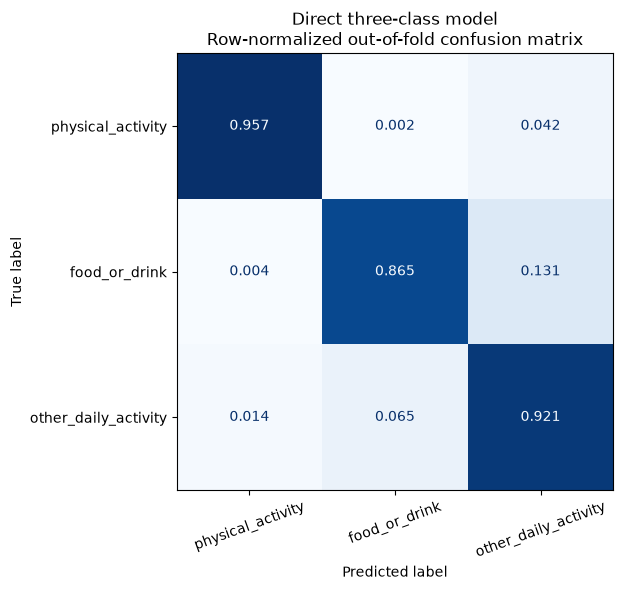

In [11]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    confusion_matrix,
)


direct_confusion_counts = confusion_matrix(
    direct_oof_predictions["y_true"],
    direct_oof_predictions["y_pred"],
    labels=BUSINESS_LABELS,
)

direct_confusion_normalized = (
    direct_confusion_counts
    / direct_confusion_counts.sum(
        axis=1,
        keepdims=True,
    )
)

display(
    pd.DataFrame(
        direct_confusion_counts,
        index=pd.Index(
            BUSINESS_LABELS,
            name="true_label",
        ),
        columns=pd.Index(
            BUSINESS_LABELS,
            name="predicted_label",
        ),
    )
)

figure, axis = plt.subplots(
    figsize=(8, 6)
)

ConfusionMatrixDisplay(
    confusion_matrix=(
        direct_confusion_normalized
    ),
    display_labels=BUSINESS_LABELS,
).plot(
    ax=axis,
    cmap="Blues",
    values_format=".3f",
    colorbar=False,
)

axis.set_title(
    "Direct three-class model\n"
    "Row-normalized out-of-fold confusion matrix"
)

axis.tick_params(
    axis="x",
    rotation=20,
)

plt.tight_layout()
plt.show()

In [12]:
ACTIVITY_NAME_BY_CODE = {
    "A": "Walking",
    "B": "Jogging",
    "C": "Stairs",
    "D": "Sitting",
    "E": "Standing",
    "F": "Typing",
    "G": "Brushing Teeth",
    "H": "Eating Soup",
    "I": "Eating Chips",
    "J": "Eating Pasta",
    "K": "Drinking from Cup",
    "L": "Eating Sandwich",
    "M": "Kicking Soccer Ball",
    "O": "Playing Catch",
    "P": "Dribbling Basketball",
    "Q": "Writing",
    "R": "Clapping",
    "S": "Folding Clothes",
}

activity_error_source = (
    direct_oof_predictions.assign(
        correct_group=lambda frame: (
            frame["y_true"]
            == frame["y_pred"]
        ),
        predicted_food=lambda frame: (
            frame["y_pred"]
            == "food_or_drink"
        ),
        food_false_positive=lambda frame: (
            (
                frame["y_true"]
                != "food_or_drink"
            )
            & (
                frame["y_pred"]
                == "food_or_drink"
            )
        ),
        food_false_negative=lambda frame: (
            (
                frame["y_true"]
                == "food_or_drink"
            )
            & (
                frame["y_pred"]
                != "food_or_drink"
            )
        ),
    )
)

activity_diagnostics = (
    activity_error_source
    .groupby(
        [
            "activity_true",
            "y_true",
        ],
        observed=True,
    )
    .agg(
        examples=(
            "array_index",
            "size",
        ),
        group_accuracy=(
            "correct_group",
            "mean",
        ),
        predicted_food_rate=(
            "predicted_food",
            "mean",
        ),
        errors=(
            "correct_group",
            lambda values: (
                ~values
            ).sum(),
        ),
        food_false_positives=(
            "food_false_positive",
            "sum",
        ),
        food_false_negatives=(
            "food_false_negative",
            "sum",
        ),
    )
    .reset_index()
    .rename(
        columns={
            "y_true": "business_label",
        }
    )
)

activity_diagnostics.insert(
    1,
    "activity_name",
    activity_diagnostics[
        "activity_true"
    ].map(
        ACTIVITY_NAME_BY_CODE
    ),
)

activity_diagnostics[
    "business_order"
] = pd.Categorical(
    activity_diagnostics[
        "business_label"
    ],
    categories=BUSINESS_LABELS,
    ordered=True,
)

activity_diagnostics = (
    activity_diagnostics
    .sort_values(
        [
            "business_order",
            "group_accuracy",
        ]
    )
    .drop(
        columns="business_order"
    )
    .reset_index(drop=True)
)

display(
    activity_diagnostics.round(4)
)

,activity_true,activity_name,business_label,examples,group_accuracy,predicted_food_rate,errors,food_false_positives,food_false_negatives
0,M,Kicking Soccer Ball,physical_activity,1435,0.9366,0.0007,91,1,0
1,P,Dribbling Basketball,physical_activity,1435,0.9387,0.0028,88,4,0
2,C,Stairs,physical_activity,1365,0.9443,0.0022,76,3,0
3,O,Playing Catch,physical_activity,1400,0.9614,0.0029,54,4,0
4,A,Walking,physical_activity,1435,0.9631,0.0014,53,2,0
5,B,Jogging,physical_activity,1400,0.9957,0.0014,6,2,0
6,L,Eating Sandwich,food_or_drink,1435,0.8425,0.8425,226,0,226
7,I,Eating Chips,food_or_drink,1435,0.8453,0.8453,222,0,222
8,J,Eating Pasta,food_or_drink,1400,0.8500,0.8500,210,0,210
9,K,Drinking from Cup,food_or_drink,1435,0.8564,0.8564,206,0,206


### Error-structure findings

The selected model separates physical activity particularly well. Only 16 of
8,470 physical-activity windows are classified as food-or-drink, and most
physical errors instead become other daily activity.

The principal business boundary is `food_or_drink` versus
`other_daily_activity`. The model misses 931 food-or-drink windows as other
activity and incorrectly assigns 653 other-activity windows to food-or-drink.

Eating Soup is the easiest intake activity, with grouped recall 0.934. Eating
Sandwich, Eating Chips, Eating Pasta, and Drinking from Cup have lower recall of
approximately 0.84–0.86.

Brushing Teeth is a useful hard negative but is not the largest false-positive
source. Sitting produces 239 food-or-drink false positives, followed by
Standing and Writing. This suggests that arm posture and low-intensity hand
motion can resemble the intake-related patterns represented in the data.

A product should therefore not send a prompt from one positive five-second
window. Moreover, food and drink occupy an artificially large share of this
controlled dataset. Because intake is much rarer in ordinary daily life,
the observed 0.902 pooled food precision should not be interpreted as expected
real-world notification precision.

## 7. Subject-level robustness

Aggregate performance can hide wearers for whom the system performs poorly.
The following analysis calculates the same metrics separately for each held-out
development subject using the selected model's out-of-fold predictions.

Particular attention is given to food-or-drink precision because a small group
of users with frequent false positives could experience unacceptable
notification fatigue even when the population-average result is strong.

In [13]:
subject_metric_rows = []

for user_id, subject_data in (
    direct_oof_predictions.groupby(
        "user_id",
        sort=True,
    )
):
    subject_folds = (
        subject_data[
            "outer_fold"
        ].unique()
    )

    assert len(subject_folds) == 1

    subject_metric_rows.append({
        "user_id": int(user_id),
        "fold": int(subject_folds[0]),
        "examples": len(subject_data),
        **calculate_business_metrics(
            subject_data["y_true"],
            subject_data["y_pred"],
        ),
    })

subject_metrics = (
    pd.DataFrame(
        subject_metric_rows
    )
    .sort_values("user_id")
    .reset_index(drop=True)
)

subject_summary = (
    subject_metrics[
        [
            "macro_f1",
            "food_precision",
            "food_recall",
            "physical_recall",
        ]
    ]
    .describe(
        percentiles=[
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
        ]
    )
    .T
)

display(
    subject_summary.round(4)
)

,count,mean,std,min,10%,25%,50%,75%,90%,max
macro_f1,41.0,0.9108,0.1035,0.4473,0.8062,0.8992,0.9414,0.9715,0.9782,0.9984
food_precision,41.0,0.8863,0.1701,0.0833,0.7419,0.8537,0.9478,0.9767,0.9942,1.0000
food_recall,41.0,0.8590,0.1994,0.0071,0.6114,0.8686,0.9371,0.9600,0.9829,1.0000
physical_recall,41.0,0.9534,0.0899,0.5200,0.8952,0.9619,0.9857,1.0000,1.0000,1.0000


In [14]:
display(
    subject_metrics
    .nsmallest(
        8,
        "macro_f1",
    )[
        [
            "user_id",
            "fold",
            "examples",
            "macro_f1",
            "food_precision",
            "food_recall",
            "physical_recall",
        ]
    ]
    .round(4)
)

display(
    subject_metrics
    .nsmallest(
        8,
        "food_precision",
    )[
        [
            "user_id",
            "fold",
            "examples",
            "macro_f1",
            "food_precision",
            "food_recall",
            "physical_recall",
        ]
    ]
    .round(4)
)

,user_id,fold,examples,macro_f1,food_precision,food_recall,physical_recall
32,1637,2,560,0.4473,0.0833,0.0071,0.5200
33,1638,4,560,0.6430,0.4365,0.3929,0.7771
28,1633,5,630,0.7883,0.8534,0.5657,0.8333
34,1642,3,560,0.7883,0.9386,0.6114,0.7600
37,1647,4,630,0.8062,0.7829,0.5771,0.9714
38,1648,5,630,0.8240,0.7419,0.6571,0.9619
7,1609,5,630,0.8364,0.9478,0.6229,0.8952
21,1624,4,630,0.8605,0.6885,0.9600,0.9857


,user_id,fold,examples,macro_f1,food_precision,food_recall,physical_recall
32,1637,2,560,0.4473,0.0833,0.0071,0.5200
33,1638,4,560,0.6430,0.4365,0.3929,0.7771
21,1624,4,630,0.8605,0.6885,0.9600,0.9857
15,1617,2,630,0.8883,0.7414,0.9829,0.9571
38,1648,5,630,0.8240,0.7419,0.6571,0.9619
37,1647,4,630,0.8062,0.7829,0.5771,0.9714
16,1619,2,630,0.9123,0.7887,0.9600,0.9952
5,1605,3,630,0.9219,0.8028,0.9771,0.9905


## 8. Paired subject-level model comparison

Subjects 1637 and 1638 are severe outliers for the selected direct model. Both
were also difficult during the earlier fine-grained activity experiments, which
suggests a broader subject-specific signal or distribution problem.

Before finalizing the grouped model, the direct and aggregated approaches are
compared for every subject. This determines whether direct training introduces
the failures or whether both approaches struggle with the same wearers.

This is a robustness diagnostic only. Model selection remains governed by the
predeclared fold-level rule.

In [15]:
def subject_metric_table(
    predictions,
):
    rows = []

    for user_id, subject_data in (
        predictions.groupby(
            "user_id",
            sort=True,
        )
    ):
        subject_folds = (
            subject_data[
                "outer_fold"
            ].unique()
        )

        assert len(subject_folds) == 1

        rows.append({
            "user_id": int(user_id),
            "fold": int(subject_folds[0]),
            **calculate_business_metrics(
                subject_data["y_true"],
                subject_data["y_pred"],
            ),
        })

    return pd.DataFrame(rows)


aggregated_subject_metrics = (
    subject_metric_table(
        aggregated_oof_predictions
    )
)

direct_subject_metrics = (
    subject_metric_table(
        direct_oof_predictions
    )
)

subject_comparison_metrics = [
    "macro_f1",
    "food_precision",
    "food_recall",
    "physical_recall",
]

subject_model_comparison = (
    aggregated_subject_metrics[
        [
            "user_id",
            "fold",
            *subject_comparison_metrics,
        ]
    ]
    .merge(
        direct_subject_metrics[
            [
                "user_id",
                "fold",
                *subject_comparison_metrics,
            ]
        ],
        on=[
            "user_id",
            "fold",
        ],
        suffixes=(
            "_aggregated",
            "_direct",
        ),
        validate="one_to_one",
    )
)

for metric in subject_comparison_metrics:
    subject_model_comparison[
        f"{metric}_difference"
    ] = (
        subject_model_comparison[
            f"{metric}_direct"
        ]
        - subject_model_comparison[
            f"{metric}_aggregated"
        ]
    )

subject_difference_columns = [
    f"{metric}_difference"
    for metric in subject_comparison_metrics
]

display(
    subject_model_comparison[
        subject_difference_columns
    ]
    .describe(
        percentiles=[
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
        ]
    )
    .T
    .round(4)
)

for metric in subject_comparison_metrics:
    differences = subject_model_comparison[
        f"{metric}_difference"
    ]

    print(
        f"{metric}: "
        f"direct better for "
        f"{(differences > 0).sum()}/41 subjects, "
        f"aggregated better for "
        f"{(differences < 0).sum()}/41"
    )

,count,mean,std,min,10%,25%,50%,75%,90%,max
macro_f1_difference,41.0,0.0035,0.0187,-0.0324,-0.0149,-0.0031,0.0029,0.0092,0.0177,0.0561
food_precision_difference,41.0,0.0199,0.0357,-0.0531,-0.0057,0.0000,0.0099,0.0310,0.0833,0.1185
food_recall_difference,41.0,-0.0059,0.0391,-0.0914,-0.0400,-0.0171,0.0000,0.0057,0.0171,0.1500
physical_recall_difference,41.0,0.0046,0.0212,-0.0514,-0.0190,0.0000,0.0048,0.0095,0.0190,0.0810


macro_f1: direct better for 24/41 subjects, aggregated better for 17/41
food_precision: direct better for 29/41 subjects, aggregated better for 7/41
food_recall: direct better for 12/41 subjects, aggregated better for 20/41
physical_recall: direct better for 21/41 subjects, aggregated better for 9/41


In [16]:
display(
    subject_model_comparison
    .nsmallest(
        8,
        "macro_f1_direct",
    )[
        [
            "user_id",
            "fold",
            "macro_f1_aggregated",
            "macro_f1_direct",
            "macro_f1_difference",
            "food_precision_aggregated",
            "food_precision_direct",
            "food_precision_difference",
            "food_recall_aggregated",
            "food_recall_direct",
        ]
    ]
    .round(4)
)

,user_id,fold,macro_f1_aggregated,macro_f1_direct,macro_f1_difference,food_precision_aggregated,food_precision_direct,food_precision_difference,food_recall_aggregated,food_recall_direct
32,1637,2,0.4396,0.4473,0.0077,0.0000,0.0833,0.0833,0.0000,0.0071
33,1638,4,0.5869,0.6430,0.0561,0.3469,0.4365,0.0896,0.2429,0.3929
28,1633,5,0.7769,0.7883,0.0114,0.8309,0.8534,0.0226,0.6457,0.5657
34,1642,3,0.7989,0.7883,-0.0106,0.9322,0.9386,0.0064,0.6286,0.6114
37,1647,4,0.8376,0.8062,-0.0314,0.8099,0.7829,-0.0269,0.6571,0.5771
38,1648,5,0.8011,0.8240,0.0230,0.7007,0.7419,0.0413,0.5886,0.6571
7,1609,5,0.8351,0.8364,0.0013,0.9464,0.9478,0.0014,0.6057,0.6229
21,1624,4,0.8427,0.8605,0.0177,0.6770,0.6885,0.0115,0.9943,0.9600


### Subject-comparison findings

The direct model's advantage is not caused by only one or two subjects. It
improves macro-F1 for 24 of 41 subjects and food-or-drink precision for 29,
while the aggregated approach provides higher food precision for only seven.

The food-recall trade-off is also broadly distributed: direct training produces
lower recall for 20 subjects and higher recall for 12. This confirms that the
precision improvement is accompanied by a real, although relatively small,
change in operating behavior.

Subjects 1637 and 1638 remain the most difficult under both approaches. Direct
training slightly improves subject 1637 and substantially improves subject
1638, so their failures were not introduced by target grouping. Their poor
performance is consistent with the earlier activity-recognition experiments and
indicates unresolved wearer-specific distribution shift.

## 9. Conclusions and development artifact

The direct three-class histogram-gradient-boosting model is selected as the
window-level grouped classifier.

It reaches mean subject-fold macro-F1 0.9158 ± 0.0262 and improves mean
food-or-drink precision from 0.8808 to 0.9008 relative to the aggregated
18-class reference. Its pooled food-or-drink precision, recall, and F1 are
0.9019, 0.8654, and 0.8833.

The result establishes a strong development classifier, not a production-ready
notification system. Important limitations remain:

- subject performance ranges widely, with severe failures for subjects 1637
  and 1638;
- most errors occur between food-or-drink and other daily activity;
- sitting is the largest observed source of food false positives;
- the controlled dataset greatly overrepresents food activity relative to
  ordinary life;
- five-second predictions have not yet been converted into events;
- the original test set is closed and cannot provide an unbiased final
  evaluation of this new business target.

The selected out-of-fold probabilities are saved for the next business-policy
stage. No model is fitted on all development subjects in this notebook.

In [17]:
import hashlib


BUSINESS_ARTIFACT_DIR = (
    PROJECT_ROOT
    / "business_case"
    / "artifacts"
)

MAPPING_PATH = (
    BUSINESS_ARTIFACT_DIR
    / "activity_group_mapping.json"
)

RESULT_PATH = (
    BUSINESS_ARTIFACT_DIR
    / "grouped_target_result.json"
)

DIRECT_OOF_PATH = (
    BUSINESS_ARTIFACT_DIR
    / "direct_oof_predictions.parquet"
)

BUSINESS_ARTIFACT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

assert selected_approach == (
    "direct_3_class"
)

mapping_record = {
    "schema_version": 1,
    "business_labels": BUSINESS_LABELS,
    "activity_code_to_business_label": (
        BUSINESS_GROUP_BY_ACTIVITY
    ),
    "activity_code_to_name": (
        ACTIVITY_NAME_BY_CODE
    ),
}

MAPPING_PATH.write_text(
    json.dumps(
        mapping_record,
        indent=2,
    ),
    encoding="utf-8",
)

direct_oof_predictions.to_parquet(
    DIRECT_OOF_PATH,
    index=False,
    compression="zstd",
)


def file_sha256(path):
    digest = hashlib.sha256()

    with path.open("rb") as file:
        for chunk in iter(
            lambda: file.read(
                1024 * 1024
            ),
            b"",
        ):
            digest.update(chunk)

    return digest.hexdigest()


def model_result_record(
    summary,
    fold_metrics,
    group_metrics,
):
    return {
        "mean_accuracy": float(
            summary.loc[
                "accuracy",
                "mean",
            ]
        ),
        "mean_balanced_accuracy": float(
            summary.loc[
                "balanced_accuracy",
                "mean",
            ]
        ),
        "mean_macro_f1": float(
            summary.loc[
                "macro_f1",
                "mean",
            ]
        ),
        "macro_f1_fold_std": float(
            summary.loc[
                "macro_f1",
                "std",
            ]
        ),
        "mean_food_precision": float(
            summary.loc[
                "food_precision",
                "mean",
            ]
        ),
        "mean_food_recall": float(
            summary.loc[
                "food_recall",
                "mean",
            ]
        ),
        "mean_physical_recall": float(
            summary.loc[
                "physical_recall",
                "mean",
            ]
        ),
        "macro_f1_by_fold": {
            str(int(row.fold)): float(
                row.macro_f1
            )
            for row in (
                fold_metrics.itertuples(
                    index=False
                )
            )
        },
        "pooled_group_metrics": {
            str(label): {
                "precision": float(
                    row["precision"]
                ),
                "recall": float(
                    row["recall"]
                ),
                "f1": float(
                    row["f1"]
                ),
                "support": int(
                    row["support"]
                ),
            }
            for label, row in (
                group_metrics.iterrows()
            )
        },
    }


weakest_subjects = (
    direct_subject_metrics
    .nsmallest(
        5,
        "macro_f1",
    )
)

result_record = {
    "schema_version": 1,
    "status": (
        "development_selected_"
        "without_unbiased_final_test"
    ),
    "selection_data": (
        "41 development subjects only"
    ),
    "examples": int(len(y_business)),
    "features": int(X.shape[1]),
    "folds": 5,
    "window_seconds": 5.0,
    "target_mapping": (
        "business_case/artifacts/"
        "activity_group_mapping.json"
    ),
    "estimator": {
        "class": (
            "sklearn.ensemble."
            "HistGradientBoostingClassifier"
        ),
        "parameters": HGB_PARAMETERS,
    },
    "results": {
        "aggregated_18_class": (
            model_result_record(
                aggregated_summary,
                aggregated_fold_metrics,
                aggregated_group_metrics,
            )
        ),
        "direct_3_class": (
            model_result_record(
                direct_summary,
                direct_fold_metrics,
                direct_group_metrics,
            )
        ),
    },
    "selection": {
        "selected_approach": (
            selected_approach
        ),
        "macro_f1_difference": float(
            macro_f1_difference
        ),
        "food_precision_difference": float(
            food_precision_difference
        ),
        "practical_macro_f1_tie": bool(
            practical_macro_f1_tie
        ),
        "reason": (
            "Macro-F1 was within the "
            "0.01 practical-tie range; "
            "the direct model had higher "
            "mean food-or-drink precision."
        ),
    },
    "subject_robustness": {
        "macro_f1_min": float(
            direct_subject_metrics[
                "macro_f1"
            ].min()
        ),
        "macro_f1_median": float(
            direct_subject_metrics[
                "macro_f1"
            ].median()
        ),
        "macro_f1_max": float(
            direct_subject_metrics[
                "macro_f1"
            ].max()
        ),
        "weakest_subjects": [
            {
                "user_id": int(
                    row.user_id
                ),
                "macro_f1": float(
                    row.macro_f1
                ),
                "food_precision": float(
                    row.food_precision
                ),
                "food_recall": float(
                    row.food_recall
                ),
            }
            for row in (
                weakest_subjects.itertuples(
                    index=False
                )
            )
        ],
    },
    "selected_oof_predictions": {
        "artifact": (
            "business_case/artifacts/"
            "direct_oof_predictions.parquet"
        ),
        "rows": int(
            len(
                direct_oof_predictions
            )
        ),
        "sha256": file_sha256(
            DIRECT_OOF_PATH
        ),
    },
    "test_status": (
        "Original reserved test set was "
        "not accessed; a new independent "
        "subject population is required."
    ),
}

RESULT_PATH.write_text(
    json.dumps(
        result_record,
        indent=2,
    ),
    encoding="utf-8",
)

print(
    "Saved mapping:",
    MAPPING_PATH.relative_to(
        PROJECT_ROOT
    ),
)

print(
    "Saved result:",
    RESULT_PATH.relative_to(
        PROJECT_ROOT
    ),
)

print(
    "Saved local OOF predictions:",
    DIRECT_OOF_PATH.relative_to(
        PROJECT_ROOT
    ),
)

print(
    "OOF SHA-256:",
    result_record[
        "selected_oof_predictions"
    ][
        "sha256"
    ],
)

Saved mapping: business_case/artifacts/activity_group_mapping.json
Saved result: business_case/artifacts/grouped_target_result.json
Saved local OOF predictions: business_case/artifacts/direct_oof_predictions.parquet
OOF SHA-256: eab73581db58739527bafae616b81136ccb278496e7c814c90db435ce2ae9f66
